# Solutions to notebook 5: Units and measurement uncertainty

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/sympy-for-engineers/blob/main/solutions/05_units_and_uncertainty.ipynb)

Worked solutions to the exercises at the end of [notebook 5](../notebooks/05_units_and_uncertainty.ipynb).
Try each exercise yourself before reading its solution: the struggle is where the learning happens.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from sympy.physics import units as u

sp.init_printing(use_latex="mathjax")
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})


# the function defined in 5.3 of the lesson, repeated here because exercises 3, 4 and 5 use it
def propagate(f, uncertainties):
    """Standard uncertainty of f, given {symbol: its uncertainty symbol or value}."""
    return sp.sqrt(sum((sp.diff(f, x) * s) ** 2 for x, s in uncertainties.items()))

## Exercise 1

Convert a heat-transfer coefficient of 25 W/(m²·K) to SI base units, and a density of
62.4 lb/ft³ to kg/m³.

In [2]:
h_coeff = 25 * u.watt / (u.meter**2 * u.kelvin)
h_base = u.convert_to(h_coeff, [u.kilogram, u.meter, u.second, u.kelvin])

density = 62.4 * u.pound / u.foot**3
density_SI = u.convert_to(density, u.kilogram / u.meter**3)

h_base, density_SI.n(5)

⎛ 25⋅kilogram    999.55⋅kilogram⎞
⎜──────────────, ───────────────⎟
⎜             3           3     ⎟
⎝kelvin⋅second       meter      ⎠

In [3]:
# verify by hand: 1 W = 1 kg m^2/s^3, so the m^2 cancels and W/(m^2 K) = kg/(s^3 K)
assert h_base == 25 * u.kilogram / (u.second**3 * u.kelvin)

# verify by hand: 1 lb = 0.45359237 kg and 1 ft = 0.3048 m exactly
density_number = density_SI / (u.kilogram / u.meter**3)
assert density_number.is_number
assert abs(density_number - 62.4 * 0.45359237 / 0.3048**3) < 1e-9

**Answer.** $25\ \mathrm{W/(m^2\,K)} = 25\ \mathrm{kg/(s^3\,K)}$: the metres cancel completely.
$62.4\ \mathrm{lb/ft^3} = 999.6\ \mathrm{kg/m^3}$, the density of water, which is where the
figure 62.4 comes from.

## Exercise 2

Attach units to the Stokes settling velocity of notebook 1 and confirm it comes out in m/s.

In [4]:
# the formula, derived as in notebook 1
Rp, rho_p, rho_f, g, mu_f, vt = sp.symbols("R_p rho_p rho_f g mu v_t", positive=True)

weight = sp.Rational(4, 3) * sp.pi * Rp**3 * (rho_p - rho_f) * g
drag = 6 * sp.pi * mu_f * Rp * vt
vt_expr = sp.solve(sp.Eq(weight, drag), vt)[0]
vt_expr

    2              
2⋅Rₚ ⋅g⋅(-ρ_f + ρₚ)
───────────────────
        9⋅μ        

In [5]:
# the sand grain of notebook 1, each value with its unit (the radius in micrometres)
sand = {
    Rp: 50 * u.micrometer,
    rho_p: 2650 * u.kilogram / u.meter**3,
    rho_f: 998 * u.kilogram / u.meter**3,
    mu_f: 1.0e-3 * u.pascal * u.second,
    g: 9.81 * u.meter / u.second**2,
}
SI_base = [u.kilogram, u.meter, u.second]

vt_units = u.convert_to(vt_expr.subs(sand), SI_base)
vt_units, u.convert_to(vt_units, u.mm / u.second)

⎛0.0090034⋅meter  9.0034⋅millimeter⎞
⎜───────────────, ─────────────────⎟
⎝    second            second      ⎠

In [6]:
# verify: dividing by m/s leaves a pure number, so the unit is m/s and nothing else
vt_number = vt_units / (u.meter / u.second)
assert vt_number.is_number

# verify: the same number as notebook 1, computed with plain floats in SI units
vt_plain = 2 * (50e-6) ** 2 * 9.81 * (2650 - 998) / (9 * 1.0e-3)
assert abs(vt_number / vt_plain - 1) < 1e-9

# a wrong formula is caught: with R_p instead of R_p**2 the result is not a velocity
wrong = u.convert_to((vt_expr / Rp).subs(sand), SI_base)
assert not (wrong / (u.meter / u.second)).is_number
wrong

180.068
───────
second 

**Answer.** $v_t = \dfrac{2R_p^2\,g\,(\rho_p - \rho_f)}{9\mu}$ has units
$\dfrac{\mathrm{m^2 \cdot m/s^2 \cdot kg/m^3}}{\mathrm{kg/(m\,s)}} = \mathrm{m/s}$.
With units attached the sand grain gives $v_t = 0.0090$ m/s (9.0 mm/s), the value of notebook 1,
and the micrometres are converted automatically.

## Exercise 3

A pendulum of length $L = 1.000 \pm 0.002$ m has a period $T = 2.007 \pm 0.005$ s. Find
$g = 4\pi^2 L / T^2$ and its uncertainty. Which measurement should be improved?

In [7]:
L, T = sp.symbols("L T", positive=True)
s_L, s_T = sp.symbols("sigma_L sigma_T", positive=True)

g_expr = 4 * sp.pi**2 * L / T**2
sigma_g = propagate(g_expr, {L: s_L, T: s_T})
sp.simplify(sigma_g / g_expr)

   _____________________
  ╱    2    2    2    2 
╲╱  4⋅L ⋅σ_T  + T ⋅σ_L  
────────────────────────
          L⋅T           

In [8]:
pendulum = {L: 1.000, T: 2.007, s_L: 0.002, s_T: 0.005}       # m, s, m, s

g_val = float(g_expr.subs(pendulum))
sigma_g_val = float(sigma_g.subs(pendulum))
print(f"g = ({g_val:.3f} ± {sigma_g_val:.3f}) m/s²   ({sigma_g_val / g_val:.2%})")

# share of each measurement in the variance of g
shares = {
    str(x): float(((sp.diff(g_expr, x) * s) ** 2 / sigma_g**2).subs(pendulum))
    for x, s in ((L, s_L), (T, s_T))
}
shares

g = (9.801 ± 0.053) m/s²   (0.54%)


{'L': 0.13876402785457612, 'T': 0.861235972145424}

In [9]:
# verify 1: the product-of-powers rule by hand, (s_g/g)^2 = (s_L/L)^2 + 4 (s_T/T)^2
relative_hand = np.sqrt((0.002 / 1.000) ** 2 + 4 * (0.005 / 2.007) ** 2)
assert abs(sigma_g_val / g_val - relative_hand) < 1e-12
assert abs(sum(shares.values()) - 1) < 1e-12

# verify 2: a Monte Carlo simulation, which uses no derivatives
rng = np.random.default_rng(seed=1)
N = 200_000
g_samples = 4 * np.pi**2 * rng.normal(1.000, 0.002, N) / rng.normal(2.007, 0.005, N) ** 2
assert abs(g_samples.std() / sigma_g_val - 1) < 0.03
print(f"propagation formula: {sigma_g_val:.4f} m/s²   Monte Carlo: {g_samples.std():.4f} m/s²")

propagation formula: 0.0526 m/s²   Monte Carlo: 0.0525 m/s²


**Answer.** $g = 9.80 \pm 0.05$ m/s² (9.801 ± 0.053 m/s², a relative uncertainty of 0.54 %),
consistent with the standard value 9.81 m/s².

The period should be improved. Its relative uncertainty (0.25 %) is only slightly larger than
that of the length (0.20 %), but $T$ enters squared, so its contribution is doubled and it
accounts for 86 % of the variance. Timing 20 swings instead of one would cut $\sigma_T$ by a
factor of 20 at no cost.

## Exercise 4

The density of a cylinder is $\rho = 4m/(\pi d^2 h)$. Derive the relative uncertainty with
`propagate` and compare it with the product-of-powers rule.

In [10]:
m, d, h = sp.symbols("m d h", positive=True)
s_m, s_d, s_h = sp.symbols("sigma_m sigma_d sigma_h", positive=True)

rho_cyl = 4 * m / (sp.pi * d**2 * h)
relative = sp.simplify(propagate(rho_cyl, {m: s_m, d: s_d, h: s_h}) / rho_cyl)
relative

   ______________________________________
  ╱  2  2   2    2  2   2      2  2    2 
╲╱  d ⋅h ⋅σₘ  + d ⋅m ⋅σₕ  + 4⋅h ⋅m ⋅σ_d  
─────────────────────────────────────────
                  d⋅h⋅m                  

In [11]:
# verify 1: product-of-powers rule for rho ~ m^1 d^-2 h^-1: each exponent squared multiplies
# the squared relative uncertainty
expected = 1**2 * (s_m / m) ** 2 + (-2) ** 2 * (s_d / d) ** 2 + (-1) ** 2 * (s_h / h) ** 2
assert sp.simplify(relative**2 - expected) == 0

# verify 2: numbers. With 1 % on every measurement the rule gives sqrt(1 + 4 + 1) = 2.45 %
one_percent = {s_m: m / 100, s_d: d / 100, s_h: h / 100}
assert sp.simplify(relative.subs(one_percent) - sp.sqrt(6) / 100) == 0
float(relative.subs(one_percent))

0.024494897427831782

**Answer.**
$\dfrac{\sigma_\rho}{\rho} = \sqrt{\left(\dfrac{\sigma_m}{m}\right)^2 + 4\left(\dfrac{\sigma_d}{d}\right)^2 + \left(\dfrac{\sigma_h}{h}\right)^2}$,
exactly what the product-of-powers rule predicts for $\rho \propto m^{1} d^{-2} h^{-1}$. The
diameter counts four times in the variance, so it deserves the most careful measurement.

## Exercise 5

Repeat the Monte Carlo check with the radius uncertainty raised to 10 %. Compare the
standard deviation and the mean of the simulated viscosities with the propagation result.
Is the distribution still symmetric?

In [12]:
# the viscometer of 5.4, with sigma_R raised from 1 % to 10 % of R
dP, R, Q, L = sp.symbols("Delta_P R Q L", positive=True)
s_dP, s_R, s_Q, s_L = sp.symbols("sigma_Delta_P sigma_R sigma_Q sigma_L", positive=True)

mu = sp.pi * dP * R**4 / (8 * Q * L)
sigmas = {dP: s_dP, R: s_R, Q: s_Q, L: s_L}
sigma_mu = propagate(mu, sigmas)

measured = {dP: 5000.0, R: 0.50e-3, Q: 1.2e-6, L: 0.100}          # Pa, m, m^3/s, m
uncert = {s_dP: 50.0, s_R: 0.05e-3, s_Q: 0.018e-6, s_L: 0.5e-3}   # 1 %, 10 %, 1.5 %, 0.5 %

mu_val = float(mu.subs(measured))
sigma_val = float(sigma_mu.subs({**measured, **uncert}))
print(f"propagation formula: mu = ({mu_val * 1e3:.3f} ± {sigma_val * 1e3:.3f}) mPa·s   ({sigma_val / mu_val:.1%})")

propagation formula: mu = (1.023 ± 0.410) mPa·s   (40.0%)


In [13]:
rng = np.random.default_rng(seed=1)
N = 200_000
samples = [rng.normal(measured[x], uncert[s], N) for x, s in sigmas.items()]

mu_fun = sp.lambdify(list(sigmas), mu, "numpy")
mu_samples = mu_fun(*samples)

mc_mean, mc_std, mc_median = mu_samples.mean(), mu_samples.std(), np.median(mu_samples)
skewness = np.mean(((mu_samples - mc_mean) / mc_std) ** 3)       # zero for a symmetric distribution
low, high = np.percentile(mu_samples, [2.5, 97.5])

print(f"Monte Carlo: mean {mc_mean * 1e3:.3f}, median {mc_median * 1e3:.3f}, std {mc_std * 1e3:.3f} mPa·s")
print(f"std: Monte Carlo / formula = {mc_std / sigma_val:.3f}     mean / nominal value = {mc_mean / mu_val:.3f}")
print(f"skewness {skewness:.2f}     95 % interval {low * 1e3:.2f} to {high * 1e3:.2f} mPa·s")

Monte Carlo: mean 1.083, median 1.022, std 0.429 mPa·s
std: Monte Carlo / formula = 1.048     mean / nominal value = 1.059
skewness 0.91     95 % interval 0.43 to 2.09 mPa·s


In [14]:
# the agreement test of the lesson (within 3 %) now fails, and the distribution is skewed
assert abs(mc_std / sigma_val - 1) > 0.03
assert skewness > 0.5 and mc_mean > mc_median

# verify against exact results for a normal variable: with eps = sigma_R / R,
# mean(R^4) = R^4 (1 + 6 eps^2 + 3 eps^4)   and   mean(R^8) = R^8 (1 + 28 eps^2 + 210 eps^4 + ...)
eps = 0.10
mean_exact = 1 + 6 * eps**2 + 3 * eps**4
std_exact = np.sqrt(1 + 28 * eps**2 + 210 * eps**4 + 420 * eps**6 + 105 * eps**8 - mean_exact**2)
assert abs(mc_mean / mu_val / mean_exact - 1) < 0.005        # the radius causes almost all of the shift
assert abs(mc_std / mu_val / std_exact - 1) < 0.02
print(f"exact, radius only: mean / nominal = {mean_exact:.3f}, std / nominal = {std_exact:.3f}")

exact, radius only: mean / nominal = 1.060, std / nominal = 0.421


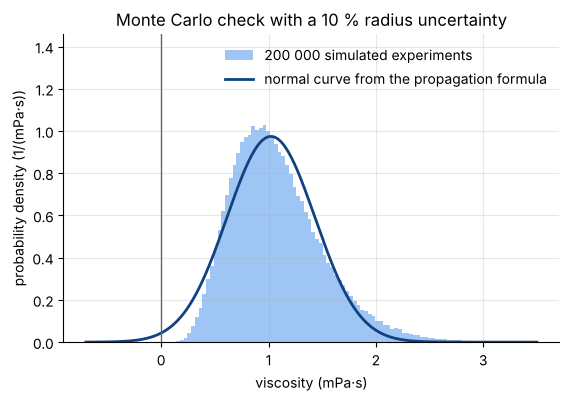

In [15]:
fig, ax = plt.subplots()
ax.hist(mu_samples * 1e3, bins=120, range=(-0.7, 3.5), density=True, color="#9ec5f4",
        label="200 000 simulated experiments")
grid = np.linspace(-0.7, 3.5, 300)
normal_curve = np.exp(-0.5 * ((grid - mu_val * 1e3) / (sigma_val * 1e3)) ** 2) / (sigma_val * 1e3 * np.sqrt(2 * np.pi))
ax.plot(grid, normal_curve, color="#104281", label="normal curve from the propagation formula")
ax.axvline(0, color="0.4", lw=1)
ax.set(xlabel="viscosity (mPa·s)", ylabel="probability density (1/(mPa·s))",
       title="Monte Carlo check with a 10 % radius uncertainty")
ax.set_ylim(top=1.35 * ax.get_ylim()[1])
ax.legend(frameon=False, loc="upper right");

**Answer.** The propagation formula gives $\mu = 1.02 \pm 0.41$ mPa·s (40 %). The Monte Carlo
simulation gives a standard deviation of 0.43 mPa·s, about 5 % larger, and a mean of 1.08 mPa·s,
about 6 % above the value computed from the measured radius. In the lesson the two estimates
agreed within 1 %.

The distribution is no longer symmetric. Because $\mu \propto R^4$, a radius that is 10 % too
large raises $\mu$ by 46 %, while one that is 10 % too small lowers it by only 34 %. The
histogram has a long tail to the right (skewness about 0.9, mean above median), and its 95 %
interval runs from about 0.43 to 2.09 mPa·s. The symmetric normal curve of the first-order
formula misses this and even assigns some probability to negative viscosities. With
uncertainties this large, report the Monte Carlo interval.